In [3]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

In [5]:
# read the data
df = pd.read_csv('AirPassengers.csv')
df

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


### Data pre-processing

In [7]:
# change the names of columns
df.columns = ['Date', 'Number of Passengers']
df.head()

,Date,Number of Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


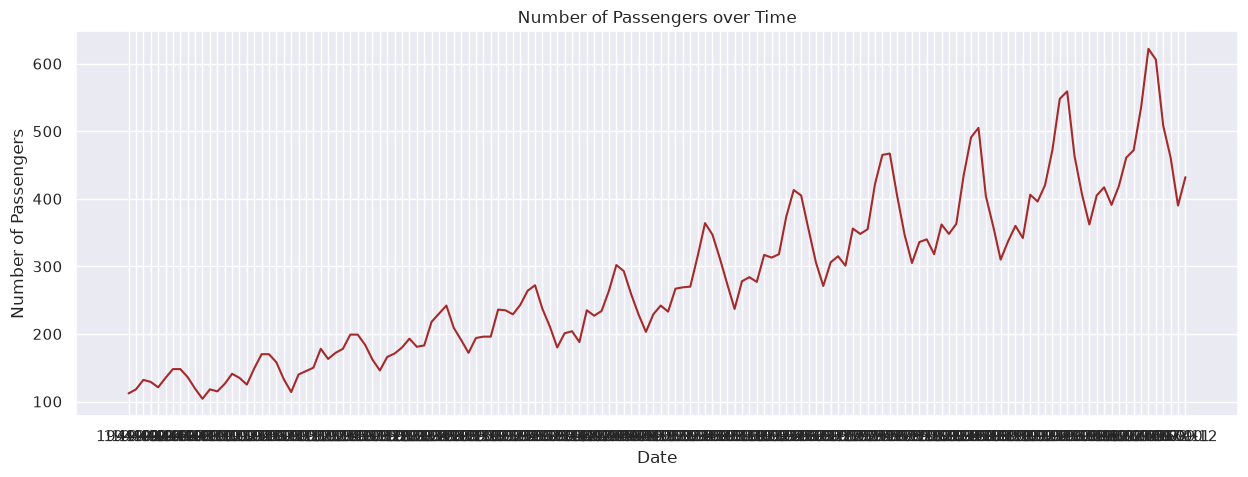

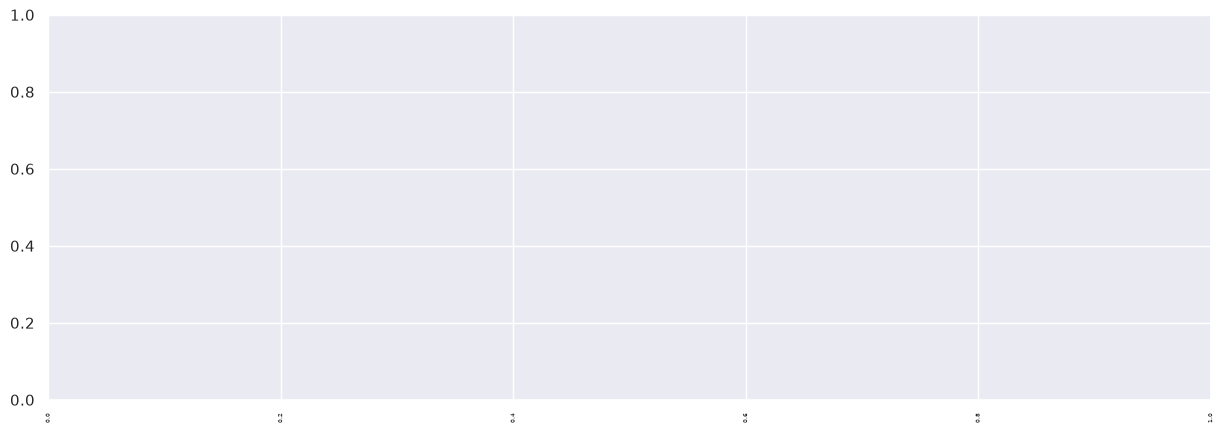

In [28]:
# plot the data using seaborn
sns.set(rc={'figure.figsize':(15,5)})
sns.lineplot(x='Date', y='Number of Passengers', color = "brown", data=df)

# plot the data
plt.xlabel('Date')
plt.ylabel('Number of Passengers')
plt.title('Number of Passengers over Time')
plt.show()

# rotate the x-axis ticks
plt.xticks(rotation=90, fontsize=4) 

# make same plot using plotly
import plotly.express as px
fig = px.line(df, x='Date', y='Number of Passengers', title='Number of Passengers over Time')

# change the x-axis limits
fig.update_xaxes(range=['1949-01-01', '1960-12-31'])
fig.show() 

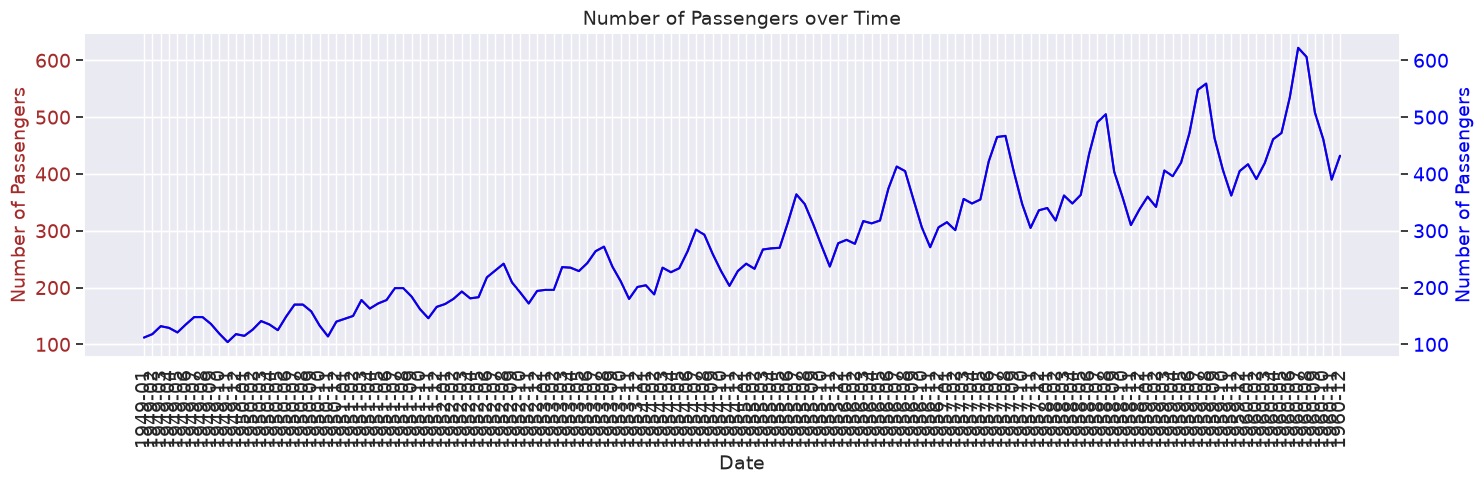

In [ ]:
# Create a figure and its main axes
fig, ax = plt.subplots(figsize=(15, 5))

# Plot passenger data on the left y-axis
ax.plot(
    df['Date'],
    df['Number of Passengers'],
    color='brown'
)

# Configure the left y-axis and plot title
ax.set_xlabel('Date', fontsize=14)
ax.set_ylabel('Number of Passengers', color='brown', fontsize=14)
ax.set_title('Number of Passengers over Time', fontsize=14)

# Customize tick labels
ax.tick_params(axis='y', labelcolor='brown', labelsize=14)
ax.tick_params(axis='x', labelsize=14, rotation=90)

# Create a second y-axis sharing the same x-axis
ax2 = ax.twinx()

# Plot passenger data on the right y-axis
ax2.plot(
    df['Date'],
    df['Number of Passengers'],
    color='blue'
)

# Configure the right y-axis
ax2.set_ylabel('Number of Passengers', color='blue', fontsize=14)
ax2.tick_params(axis='y', labelcolor='blue', labelsize=14)

# Adjust spacing and display the plot
plt.tight_layout()
plt.show()

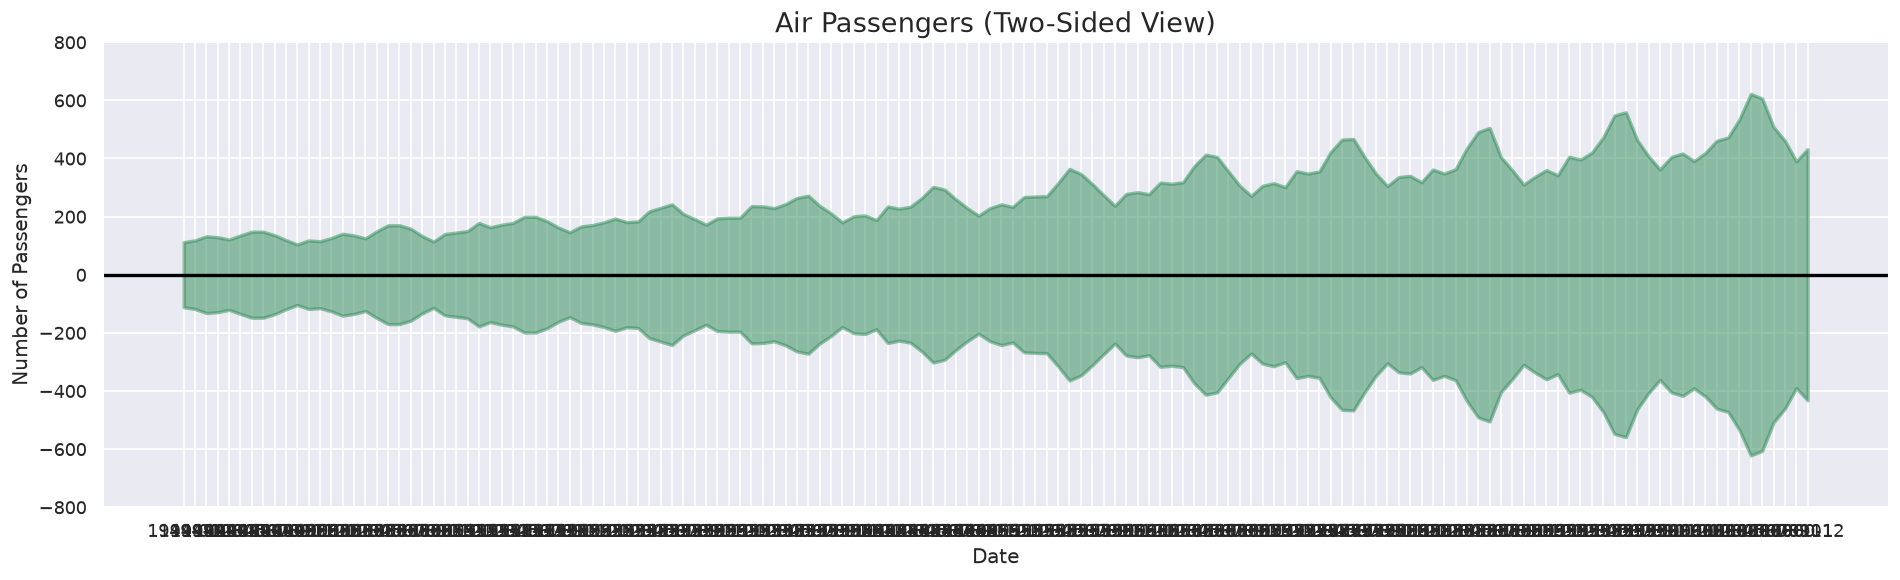

In [36]:

# Extract date and passenger values
x = df['Date'].values
y1 = df['Number of Passengers'].values

# Create the figure and axes
fig, ax = plt.subplots(figsize=(16, 5), dpi=120)

# Fill the area between positive and negative passenger values
ax.fill_between(
    x,
    y1,
    -y1,
    alpha=0.5,
    linewidth=2,
    color='seagreen'
)

# Set the y-axis limits
ax.set_ylim(-800, 800)

# Add title and axis labels
ax.set_title('Air Passengers (Two-Sided View)', fontsize=16)
ax.set_xlabel('Date')
ax.set_ylabel('Number of Passengers')

# Draw a horizontal zero line
ax.axhline(y=0, color='black', linewidth=2)

# Display the plot
plt.tight_layout()
plt.show()


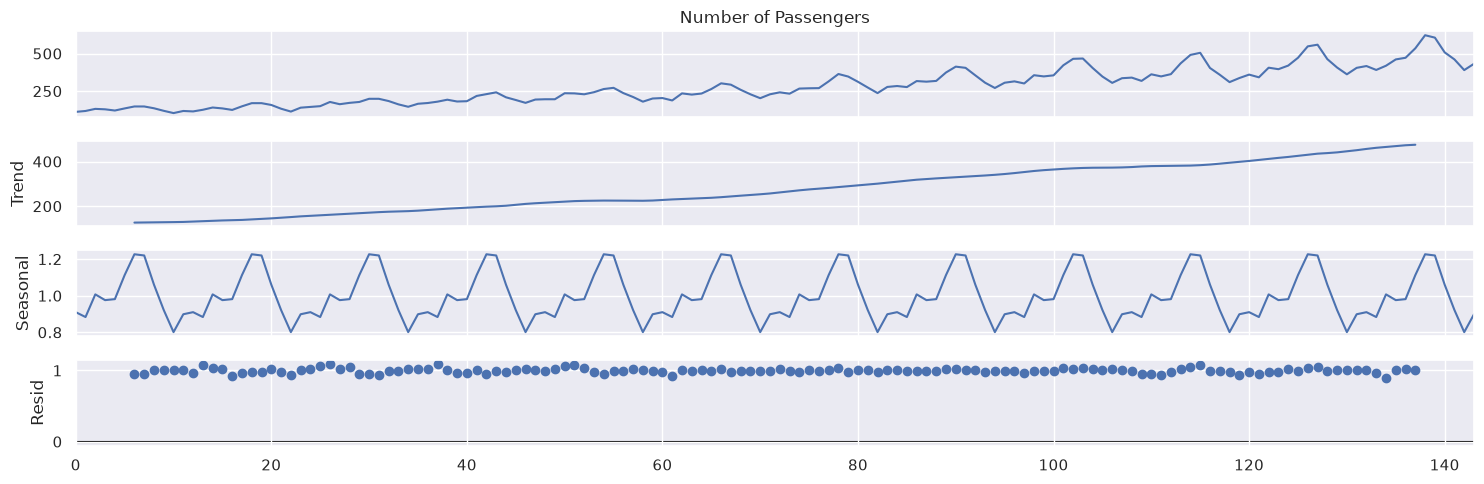

In [42]:
# decompose the data
result = seasonal_decompose(df['Number of Passengers'], model='multiplicative', period=12)
result.plot()
# plot in plotly
fig = px.line(result.observed, x=result.observed.index, y=result.observed.values, title='Observed')
fig.show()